# Stage 7: The security market line and security pricing

The CML in Stage 5 applies to efficient portfolios, measuring risk by total volatility. A single
stock can't sit on it, because much of its volatility can be diversified away. Theory says only the
part that can't be diversified earns a reward, and beta measures that part.

The **security market line (SML)** prices every asset this way:

E(r_i) = r_f + β_i [E(r_m) − r_f]

| | CML | SML |
|---|---|---|
| Applies to | Efficient portfolios | Every asset |
| Risk measure | Volatility σ | Beta β |
| A point off the line means | The portfolio is inefficient | The asset looks mispriced |

A stock above the SML earned more than its beta justifies, so it looks underpriced. A stock below it
looks overpriced. **Alpha** is that vertical distance.

This stage measures these distances, then asks whether they can be trusted. It uses **estimation
months only**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pmo import backtest, models, pricing
from pmo import returns as ret
from pmo.config import load_config
from pmo.pipeline import dividend_data, load
from pmo.plotting import FIGURES, MUTED, SERIES_1, SERIES_2, SURFACE, apply_style

apply_style()
config = load_config()
data = load()
stocks = data.universe["symbol"].tolist()
market = config.market_proxy

excess_all = ret.select_period(data.excess, data.periods, "estimation")
excess, market_excess = excess_all[stocks], excess_all[market]
RISK_FREE = data.risk_free["rf"].loc[excess.index].mean() * 12
PREMIUM = data.factors_long.loc[:excess.index.max(), "MKT_RF"].mean() * 12
print(f"Risk-free {RISK_FREE:.1%}; long-run market premium {PREMIUM:.1%}")

Risk-free 6.4%; long-run market premium 8.5%


## 1. The security market line

The solid line is the SML from theory. The dashed line is the best fit through the 25 stocks.

Alpha in the table is measured against the SML, but nearly every stock is above it, for the
survivorship reasons from Stage 5. So `relative_alpha` subtracts the average, which compares stocks
with each other and removes what they all share.

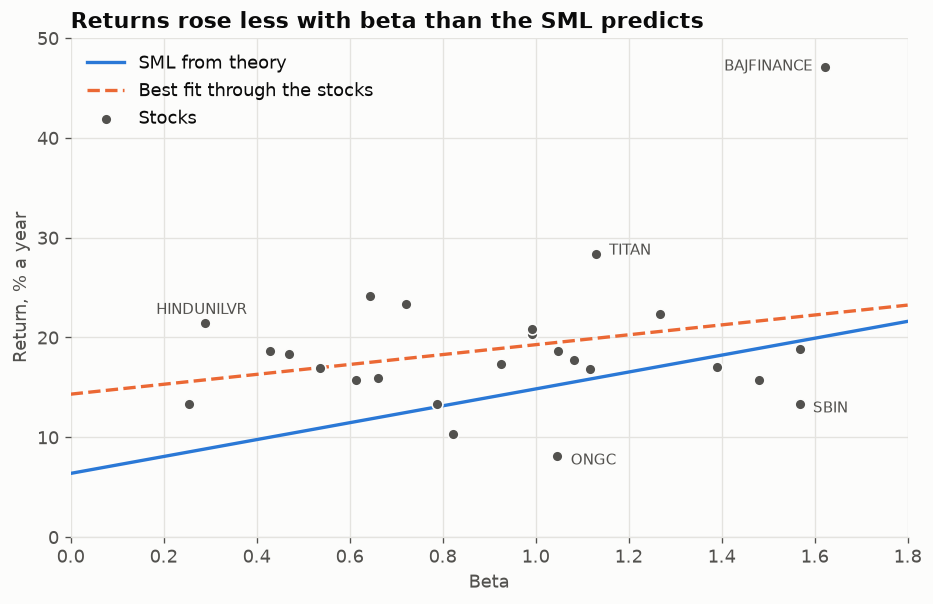

Best fit: intercept 14.3% (theory 6.4%), slope 5.0% (theory 8.5%); correlation of beta and return 0.27


,beta,required_return,realized_return,alpha,relative_alpha,relative_t
BAJFINANCE,1.623,0.201,0.471,0.318,0.244,3.585
TITAN,1.129,0.159,0.284,0.158,0.083,1.393
HCLTECH,0.644,0.118,0.242,0.143,0.068,1.132
HINDUNILVR,0.288,0.088,0.214,0.134,0.060,1.166
ASIANPAINT,0.720,0.125,0.233,0.130,0.056,1.040
NESTLEIND,0.429,0.100,0.187,0.099,0.025,0.509
TCS,0.469,0.103,0.183,0.094,0.019,0.410
MARUTI,1.268,0.171,0.223,0.090,0.016,0.267
ULTRACEMCO,0.992,0.148,0.208,0.090,0.015,0.321
KOTAKBANK,0.991,0.148,0.203,0.085,0.011,0.246


In [2]:
table = pricing.security_table(excess, market_excess, RISK_FREE, PREMIUM)
slope, intercept = np.polyfit(table["beta"], table["realized_return"], 1)
betas = np.array([0, 1.8])

fig, ax = plt.subplots(figsize=(9, 5.4))
ax.grid(axis="x")
ax.plot(betas, pricing.required_return(betas, RISK_FREE, PREMIUM) * 100, color=SERIES_1,
        label="SML from theory")
ax.plot(betas, (intercept + slope * betas) * 100, color=SERIES_2, linestyle="--",
        label="Best fit through the stocks")
ax.scatter(table["beta"], table["realized_return"] * 100, s=42, color=MUTED, edgecolor=SURFACE,
           zorder=3, label="Stocks")
labels = {"BAJFINANCE": (-8, 0, "right"), "TITAN": (8, 2, "left"), "ONGC": (8, -3, "left"),
          "SBIN": (8, -3, "left"), "HINDUNILVR": (-2, 8, "center")}
for name, (dx, dy, align) in labels.items():
    ax.annotate(name, (table.loc[name, "beta"], table.loc[name, "realized_return"] * 100),
                xytext=(dx, dy), textcoords="offset points", ha=align, va="center", fontsize=9,
                color=MUTED)
ax.set_xlim(0, 1.8)
ax.set_ylim(0, 50)
ax.set_xlabel("Beta")
ax.set_ylabel("Return, % a year")
ax.set_title("Returns rose less with beta than the SML predicts")
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIGURES / "07_security_market_line.png")
plt.show()

print(f"Best fit: intercept {intercept:.1%} (theory {RISK_FREE:.1%}), "
      f"slope {slope:.1%} (theory {PREMIUM:.1%}); "
      f"correlation of beta and return {table['beta'].corr(table['realized_return']):.2f}")
table.sort_values("relative_alpha", ascending=False).round(3)

Bonferroni's correction applies here because we are looking at 25 stocks at once. By chance alone,
about one stock in 20 would pass a t-statistic of 2.

In [3]:
flagged = table.loc[table["relative_t"].abs() > 2, ["relative_alpha", "relative_t"]]
strict = table.loc[table["relative_t"].abs() > 3.1, "relative_t"]
print(f"Stocks with |t| above 2: {len(flagged)} of {len(table)}; "
      f"after correcting for 25 tests: {len(strict)}")
flagged.round(3)

Stocks with |t| above 2: 1 of 25; after correcting for 25 tests: 1


,relative_alpha,relative_t
BAJFINANCE,0.244,3.585


## 2. How good are the betas?

The SML is only as good as its betas, and betas move over time. This compares the two halves of the
sample, then tests which estimate best predicts the next three years of beta.

In [4]:
half = len(excess) // 2
first = models.fit_factor_model(excess.iloc[:half], market_excess.iloc[:half].to_frame("MKT")).betas["MKT"]
second = models.fit_factor_model(excess.iloc[half:], market_excess.iloc[half:].to_frame("MKT")).betas["MKT"]
print(f"Correlation of betas across halves: {first.corr(second):.2f}; "
      f"average change {(first - second).abs().mean():.2f}")
errors = pricing.beta_forecast_errors(excess, market_excess)
errors.sort_values().round(3).to_frame("average_forecast_error")

Correlation of betas across halves: 0.75; average change 0.24


,average_forecast_error
Blume,0.355
Vasicek,0.377
Raw,0.404
All equal to 1,0.441


Betas persist well, but they do drift. Pulling them part of the way toward 1, as the Blume
adjustment does, predicted future betas better than the raw estimate, which is a simple improvement.

## 3. Does beta explain returns?

This is the classic Fama-MacBeth test. Each month, regress stock returns on betas estimated from
earlier months only, then average the results. CAPM predicts:

- The intercept should be zero.
- The slope should equal the market's excess return.

In [5]:
rows = {}
for window in [36, 60]:
    results = pricing.fama_macbeth(excess, market_excess, window)
    gap = results["slope"] - results["market"]
    for name, series in [("Intercept", results["intercept"]), ("Slope", results["slope"]),
                         ("Market excess return", results["market"]),
                         ("Slope minus market", gap)]:
        rows[f"{window}-month betas", name] = pricing.monthly_mean_test(series)
pd.DataFrame(rows).T.round(3)

annual_mean  standard_error  t_stat
36-month betas Intercept                   0.045           0.050   0.905
               Slope                       0.102           0.058   1.763
               Market excess return        0.081           0.052   1.577
               Slope minus market          0.020           0.051   0.396
60-month betas Intercept                   0.042           0.061   0.680
               Slope                       0.111           0.074   1.501
               Market excess return        0.093           0.061   1.537
               Slope minus market          0.018           0.062   0.296

Neither prediction can be rejected, but that isn't strong support for CAPM. The standard errors
are so wide that this test could hardly reject anything. With 25 stocks and under 10 years of test
data, it has little power.

## 4. Can the SML find mispriced stocks?

This is the practical question for the final tool. If stocks above the SML stay above it, alpha is
useful. Each year, rank stocks by trailing alpha or beta, hold the top and bottom 8 for a year, and
compare. Costs are excluded, and the holdout stays untouched.

In [6]:
def alpha_score(train):
    return models.fit_factor_model(train[stocks], train[market].to_frame("MKT")).alpha


def beta_score(train):
    return models.fit_factor_model(train[stocks], train[market].to_frame("MKT")).betas["MKT"]


strategies = {
    "High alpha": lambda train: pricing.rank_portfolio(alpha_score(train), 8, True),
    "Low alpha": lambda train: pricing.rank_portfolio(alpha_score(train), 8, False),
    "High beta": lambda train: pricing.rank_portfolio(beta_score(train), 8, True),
    "Low beta": lambda train: pricing.rank_portfolio(beta_score(train), 8, False),
    "Equal weight": lambda train: pd.Series(1 / len(stocks), index=stocks),
    "Market proxy": lambda train: pd.Series({market: 1.0}),
}
columns = ["excess_return", "volatility", "sharpe", "max_drawdown"]
results = {window: backtest.run(excess_all, strategies, window=window, step=12)
           for window in [60, 36]}
pd.concat({f"{w}-month window": backtest.scorecard(r)[columns] for w, r in results.items()}).round(3)

excess_return  volatility  sharpe  max_drawdown
60-month window High alpha            0.155       0.180   0.858        -0.199
                Low alpha             0.174       0.190   0.915        -0.351
                High beta             0.203       0.232   0.871        -0.377
                Low beta              0.086       0.142   0.607        -0.190
                Equal weight          0.147       0.162   0.907        -0.254
                Market proxy          0.093       0.169   0.552        -0.313
36-month window High alpha            0.157       0.179   0.879        -0.208
                Low alpha             0.144       0.206   0.698        -0.357
                High beta             0.181       0.225   0.805        -0.379
                Low beta              0.088       0.147   0.595        -0.231
                Equal weight          0.141       0.156   0.904        -0.254
                Market proxy          0.081       0.161   0.505        -0.313

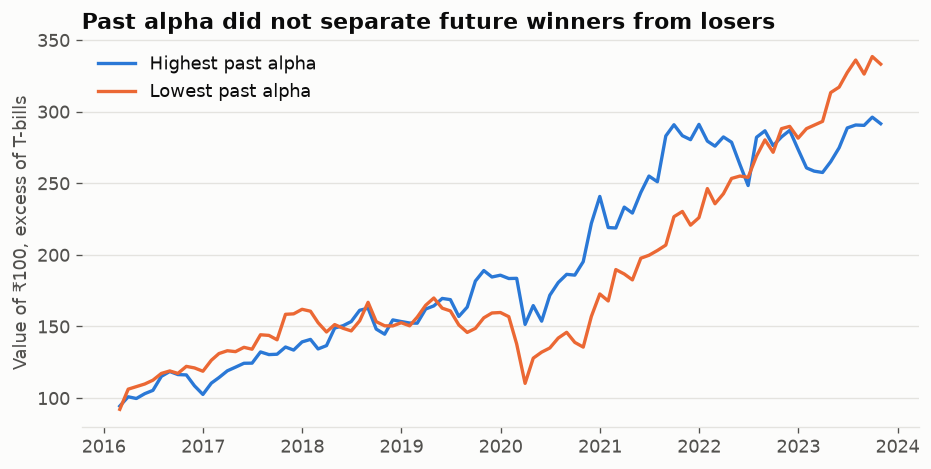

,annual_mean,standard_error,t_stat
60m: high alpha minus low alpha,-0.019,0.060,-0.317
60m: high beta minus low beta,0.116,0.072,1.608
36m: high alpha minus low alpha,0.014,0.060,0.226
36m: high beta minus low beta,0.094,0.063,1.491


In [7]:
rows = {}
for window, result in results.items():
    frame = result.returns
    rows[f"{window}m: high alpha minus low alpha"] = pricing.monthly_mean_test(
        frame["High alpha"] - frame["Low alpha"])
    rows[f"{window}m: high beta minus low beta"] = pricing.monthly_mean_test(
        frame["High beta"] - frame["Low beta"])
spreads = pd.DataFrame(rows).T

frame = results[60].returns
growth = (1 + frame[["High alpha", "Low alpha"]]).cumprod() * 100
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(growth.index, growth["High alpha"], color=SERIES_1, label="Highest past alpha")
ax.plot(growth.index, growth["Low alpha"], color=SERIES_2, label="Lowest past alpha")
ax.set_ylabel("Value of ₹100, excess of T-bills")
ax.set_title("Past alpha did not separate future winners from losers")
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIGURES / "07_alpha_persistence.png")
plt.show()
spreads.round(3)

**Past alpha told us almost nothing about the following year.** Over/undervalued flags from the SML
would have been noise here, even without costs.

High-beta stocks did earn more over this period, which fits the idea of a reward for market risk.
They also had much larger drawdowns, and this was a rising market. The return gap isn't significant.

## 5. Valuing a stock from its dividends

A stock is worth its future cash flows, discounted at the required return. The SML supplies that
discount rate k. Using Blume betas, as section 2 suggests, the simplest model is Gordon's:

P = D₀(1 + g) / (k − g)

Rather than guessing g, we can solve for it. **What growth does today's price assume?** This uses
prices and trailing dividends at the end of the estimation period, adjusted for later splits.

In [8]:
dividends, closes = dividend_data()
end = excess.index.max()
price = closes.loc[:end, stocks].iloc[-1]
paid = dividends.loc[end - pd.DateOffset(years=1) + pd.Timedelta(days=1):end, stocks].sum()
adjusted = pricing.blume_beta(table["beta"])
required = pricing.required_return(adjusted, RISK_FREE, PREMIUM)

years = dividends.groupby(dividends.index.year).sum()
LATE_GROWTH, EARLY_YEARS = 0.08, 10    # illustrative assumptions
valuation = pd.DataFrame({
    "dividend_yield": paid / price,
    "required_return": required,
    "gordon_implied_growth": pricing.implied_growth(price, paid, required),
    "ten_year_implied_growth": [
        pricing.implied_two_stage_growth(price[s], paid[s], required[s], EARLY_YEARS, LATE_GROWTH)
        for s in stocks],
    "past_dividend_growth": ((years.loc[2021:2022, stocks].sum() / years.loc[2012:2013, stocks].sum())
                             ** (1 / 9) - 1),
})
print(f"Stocks whose Gordon growth exceeds 10% forever: "
      f"{(valuation['gordon_implied_growth'] > 0.10).sum()} of {len(valuation)}")
print(f"Stocks needing faster 10-year growth than their past record: "
      f"{(valuation['ten_year_implied_growth'] > valuation['past_dividend_growth']).sum()} of {len(valuation)}")
valuation.sort_values("ten_year_implied_growth", ascending=False).round(3)

Stocks whose Gordon growth exceeds 10% forever: 18 of 25
Stocks needing faster 10-year growth than their past record: 21 of 25


,dividend_yield,required_return,gordon_implied_growth,ten_year_implied_growth,past_dividend_growth
KOTAKBANK,0.001,0.148,0.147,0.733,0.133
BAJFINANCE,0.004,0.184,0.179,0.576,0.309
TITAN,0.003,0.156,0.152,0.540,0.129
RELIANCE,0.004,0.153,0.149,0.496,0.063
ULTRACEMCO,0.005,0.148,0.143,0.459,0.179
ICICIBANK,0.009,0.180,0.170,0.442,0.006
BHARTIARTL,0.004,0.136,0.131,0.426,0.058
MARUTI,0.009,0.164,0.154,0.402,0.237
LT,0.010,0.170,0.159,0.393,0.111
NESTLEIND,0.004,0.116,0.111,0.353,0.174


Growing faster than the whole economy forever is impossible, so a high Gordon figure shows the
single-stage model doesn't fit these companies. The two-stage version allows 10 years of faster
growth, then 8% forever, and both of those are illustrative assumptions.

The largest implied rates are not forecasts. Those companies pay out little of their earnings, so a
small dividend has to carry the whole price. A dividend model suits steady high payers such as ITC or
TCS far better than low payers such as Kotak Bank or Titan.

### Why this can't produce a price target

Small input changes move the value a lot, because of the k − g term. This repeats the calculation for
one stock across reasonable inputs.

In [9]:
name = "HINDUNILVR"
base_growth = valuation.loc[name, "ten_year_implied_growth"]
rows = {}
for k_shift in [-0.01, 0.0, 0.01]:
    rows[f"k {required[name] + k_shift:.1%}"] = {
        f"early growth {base_growth + g_shift:.1%}":
            pricing.two_stage_value(paid[name], required[name] + k_shift, base_growth + g_shift,
                                    EARLY_YEARS, LATE_GROWTH)
        for g_shift in [-0.02, 0.0, 0.02]}
values = pd.DataFrame(rows).T
print(f"{name} price: ₹{price[name]:,.0f}; range of values: "
      f"₹{values.min().min():,.0f} to ₹{values.max().max():,.0f}")
values.round(0)

HINDUNILVR price: ₹2,484; range of values: ₹1,541 to ₹4,618


,early growth 12.2%,early growth 14.2%,early growth 16.2%
k 9.8%,3313.0,3915.0,4618.0
k 10.8%,2113.0,2484.0,2916.0
k 11.8%,1541.0,1804.0,2108.0


## Stage 7 conclusions

1. **The full-sample SML looks flatter than theory:** returns rose with beta less than predicted, and
   beta explained little of the differences in return.
2. **CAPM can't be rejected, or confirmed:** the month-by-month test found a slope close to the
   market's return, so it does not confirm that flatness, but it has too little power either way.
3. **Betas are usable, and Blume betas are better:** they predicted future beta better than raw
   estimates. The practical inputs still use raw betas, and Stage 10 can test the swap.
4. **Alpha doesn't persist:** high-alpha stocks did not reliably beat low-alpha stocks the next year,
   and only Bajaj Finance stands out after correcting for multiple tests.
5. **Dividend models show assumptions, not answers:** they reveal what growth a price assumes, but
   small input changes move the value too much to give a price target.

### Decision for the final tool

The tool will show each stock's **beta and CAPM required return**, because they describe risk. It will
**not** show "undervalued" or "overvalued" labels: the evidence here doesn't support them, and they
would read like investment advice.